# Experiment 190 · Control under visual regime shifts

**Complete** · Matched-budget controller study saved · ETA 0h 00m 00s

Clip order is preserved inside each 96-frame clip. Regimes use the upper and lower 30% along the first standardized principal component of clip RGB statistics. The six statistics capture luminance, contrast, dark-pixel share, color range and horizontal/vertical texture. Clip IDs, capture groups and video and decoded-frame hashes are split across training, the controller’s monitor banks, the pilot banks and the untouched test banks. The regime split and control policy use unlabeled inputs.

Each regime block contains 6,144 arrivals. The pilot first learns A without replay, then compares zero replay and fixed 25% through B from each shared A checkpoint. The gate requires both at least 0.005 MSE forgetting on A and 0.005 MSE adaptation on B in the same trajectory for at least two of three seeds in either arm. These changes use the four final 256-arrival readouts in B and the common switch checkpoint. The gate uses fixed pilot banks. Controller fitting and decisions use separate monitor clips, and the full comparison uses an untouched final test bank.

If the gate passes, the full run alternates A–B–A–B for six seeds and two paired masks. After initial A, each policy uses exactly 256 replay updates per 1,024 arrivals and one optimizer step per arrival. The candidate rates are 0%, 25% and 50% per 256 arrivals. All replay samples from broad causal history. Random schedules sample quota-feasible plans. The threshold uses monitor-bank forgetting. MPC fits action-conditioned ridge dynamics from matched pilot-state forks and plans two blocks ahead. The objective adds a unit-weight forgetting penalty above 0.005 to current-regime MSE. Three seeds outside the pilot form the held-out controller comparison.

## Frozen regimes

| Regime | Mean luma | Dark-pixel share | Training clips | Monitor clips | Test clips |
| --- | --- | --- | --- | --- | --- |
 | A | 0.476 | 10.7% | 128 | 8 | 16 | 
 | B | 0.064 | 90.0% | 128 | 8 | 16 | 

## Pilot gate

| Replay | Seed | A forgetting | B adaptation |
| --- | --- | --- | --- |
 | zero | 2035 | +0.32991 | +0.43554 | 
 | zero | 2037 | +0.33166 | +0.46879 | 
 | zero | 2039 | +0.35654 | +0.46962 | 
 | fixed | 2035 | -0.10265 | +0.44586 | 
 | fixed | 2037 | -0.11525 | +0.47987 | 
 | fixed | 2039 | -0.12006 | +0.49528 | 

**Decision:** advance to the matched-budget controller comparison.

## Full matched-budget comparison

| Scope | Policy | Reference | Pairs | Forgetting reduction | Adaptation gain | Objective gain | Seeds improved |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | all | random | fixed | 12 | -0.01562 | +0.00758 | -0.01098 | 0/6 | 
 | all | threshold | fixed | 12 | -0.02187 | +0.02466 | -0.01788 | 0/6 | 
 | all | mpc | fixed | 12 | -0.00278 | +0.02606 | -0.00346 | 1/6 | 
 | all | mpc | random | 12 | +0.01283 | +0.01848 | +0.00752 | 6/6 | 
 | held-out | random | fixed | 6 | -0.01664 | +0.01128 | -0.01207 | 0/3 | 
 | held-out | threshold | fixed | 6 | -0.02319 | +0.02831 | -0.01762 | 0/3 | 
 | held-out | mpc | fixed | 6 | -0.00382 | +0.03563 | -0.00437 | 0/3 | 
 | held-out | mpc | random | 6 | +0.01282 | +0.02435 | +0.00771 | 3/3 | 

Positive objective gain means lower current-regime MSE plus forgetting penalty than the reference. The table averages over all three shifts and both mask draws within each seed.

## External frozen probes

| Checkpoint | Policy | Runs | Scene | Weather | Lighting | Pedestrian |
| --- | --- | --- | --- | --- | --- | --- |
 | 6144 | initial A | 12 | 39.38% | 44.55% | 94.96% | 57.11% | 
 | 12288 | fixed | 12 | 42.61% | 44.47% | 95.98% | 57.63% | 
 | 12288 | mpc | 12 | 42.41% | 44.68% | 96.29% | 58.05% | 
 | 12288 | random | 12 | 42.55% | 43.54% | 96.22% | 58.26% | 
 | 12288 | threshold | 12 | 42.10% | 43.60% | 96.06% | 58.46% | 
 | 24576 | fixed | 12 | 43.90% | 44.19% | 95.36% | 58.83% | 
 | 24576 | mpc | 12 | 43.77% | 44.88% | 96.07% | 59.06% | 
 | 24576 | random | 12 | 43.02% | 43.83% | 96.30% | 58.78% | 
 | 24576 | threshold | 12 | 43.72% | 44.03% | 96.07% | 58.49% | 

| Seed | Draw | Policy | Arrivals | Replay updates | Train time | Control time |
| --- | --- | --- | --- | --- | --- | --- |
 | 2035 | 0 | zero | 12288 | 0 | 0h 01m 34s | 0.00s | 
 | 2035 | 0 | fixed | 12288 | 1536 | 0h 01m 34s | 0.02s | 
 | 2037 | 0 | zero | 12288 | 0 | 0h 01m 35s | 0.00s | 
 | 2037 | 0 | fixed | 12288 | 1536 | 0h 01m 36s | 0.01s | 
 | 2039 | 0 | zero | 12288 | 0 | 0h 01m 36s | 0.00s | 
 | 2039 | 0 | fixed | 12288 | 1536 | 0h 01m 38s | 0.01s | 
 | 2035 | 1 | fixed | 24576 | 4608 | 0h 03m 16s | 0.00s | 
 | 2035 | 1 | random | 24576 | 4608 | 0h 03m 15s | 0.01s | 
 | 2035 | 1 | threshold | 24576 | 4608 | 0h 03m 13s | 0.15s | 
 | 2035 | 1 | mpc | 24576 | 4608 | 0h 03m 13s | 0.33s | 
 | 2035 | 2 | fixed | 24576 | 4608 | 0h 03m 13s | 0.00s | 
 | 2035 | 2 | random | 24576 | 4608 | 0h 03m 11s | 0.01s | 
 | 2035 | 2 | threshold | 24576 | 4608 | 0h 03m 09s | 0.14s | 
 | 2035 | 2 | mpc | 24576 | 4608 | 0h 03m 12s | 0.34s | 
 | 2036 | 1 | fixed | 24576 | 4608 | 0h 03m 08s | 0.00s | 
 | 2036 | 1 | random | 24576 | 4608 | 0h 03m 09s | 0.01s | 
 | 2036 | 1 | threshold | 24576 | 4608 | 0h 03m 08s | 0.14s | 
 | 2036 | 1 | mpc | 24576 | 4608 | 0h 03m 08s | 0.33s | 
 | 2036 | 2 | fixed | 24576 | 4608 | 0h 03m 11s | 0.00s | 
 | 2036 | 2 | random | 24576 | 4608 | 0h 03m 09s | 0.01s | 
 | 2036 | 2 | threshold | 24576 | 4608 | 0h 03m 08s | 0.14s | 
 | 2036 | 2 | mpc | 24576 | 4608 | 0h 03m 07s | 0.33s | 
 | 2037 | 1 | fixed | 24576 | 4608 | 0h 03m 13s | 0.00s | 
 | 2037 | 1 | random | 24576 | 4608 | 0h 03m 13s | 0.01s | 
 | 2037 | 1 | threshold | 24576 | 4608 | 0h 03m 10s | 0.14s | 
 | 2037 | 1 | mpc | 24576 | 4608 | 0h 03m 12s | 0.34s | 
 | 2037 | 2 | fixed | 24576 | 4608 | 0h 03m 18s | 0.00s | 
 | 2037 | 2 | random | 24576 | 4608 | 0h 03m 19s | 0.01s | 
 | 2037 | 2 | threshold | 24576 | 4608 | 0h 03m 21s | 0.16s | 
 | 2037 | 2 | mpc | 24576 | 4608 | 0h 03m 26s | 0.36s | 
 | 2038 | 1 | fixed | 24576 | 4608 | 0h 03m 14s | 0.00s | 
 | 2038 | 1 | random | 24576 | 4608 | 0h 03m 13s | 0.01s | 
 | 2038 | 1 | threshold | 24576 | 4608 | 0h 03m 14s | 0.16s | 
 | 2038 | 1 | mpc | 24576 | 4608 | 0h 03m 10s | 0.33s | 
 | 2038 | 2 | fixed | 24576 | 4608 | 0h 03m 08s | 0.00s | 
 | 2038 | 2 | random | 24576 | 4608 | 0h 03m 10s | 0.01s | 
 | 2038 | 2 | threshold | 24576 | 4608 | 0h 03m 11s | 0.15s | 
 | 2038 | 2 | mpc | 24576 | 4608 | 0h 03m 09s | 0.33s | 
 | 2039 | 1 | fixed | 24576 | 4608 | 0h 03m 09s | 0.00s | 
 | 2039 | 1 | random | 24576 | 4608 | 0h 03m 08s | 0.01s | 
 | 2039 | 1 | threshold | 24576 | 4608 | 0h 03m 07s | 0.14s | 
 | 2039 | 1 | mpc | 24576 | 4608 | 0h 03m 07s | 0.33s | 
 | 2039 | 2 | fixed | 24576 | 4608 | 0h 03m 08s | 0.00s | 
 | 2039 | 2 | random | 24576 | 4608 | 0h 03m 11s | 0.01s | 
 | 2039 | 2 | threshold | 24576 | 4608 | 0h 03m 12s | 0.14s | 
 | 2039 | 2 | mpc | 24576 | 4608 | 0h 03m 11s | 0.33s | 
 | 2040 | 1 | fixed | 24576 | 4608 | 0h 03m 13s | 0.00s | 
 | 2040 | 1 | random | 24576 | 4608 | 0h 03m 10s | 0.01s | 
 | 2040 | 1 | threshold | 24576 | 4608 | 0h 03m 10s | 0.14s | 
 | 2040 | 1 | mpc | 24576 | 4608 | 0h 03m 13s | 0.34s | 
 | 2040 | 2 | fixed | 24576 | 4608 | 0h 03m 11s | 0.00s | 
 | 2040 | 2 | random | 24576 | 4608 | 0h 03m 09s | 0.01s | 
 | 2040 | 2 | threshold | 24576 | 4608 | 0h 03m 09s | 0.14s | 
 | 2040 | 2 | mpc | 24576 | 4608 | 0h 03m 10s | 0.33s | 

In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-shift-control')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


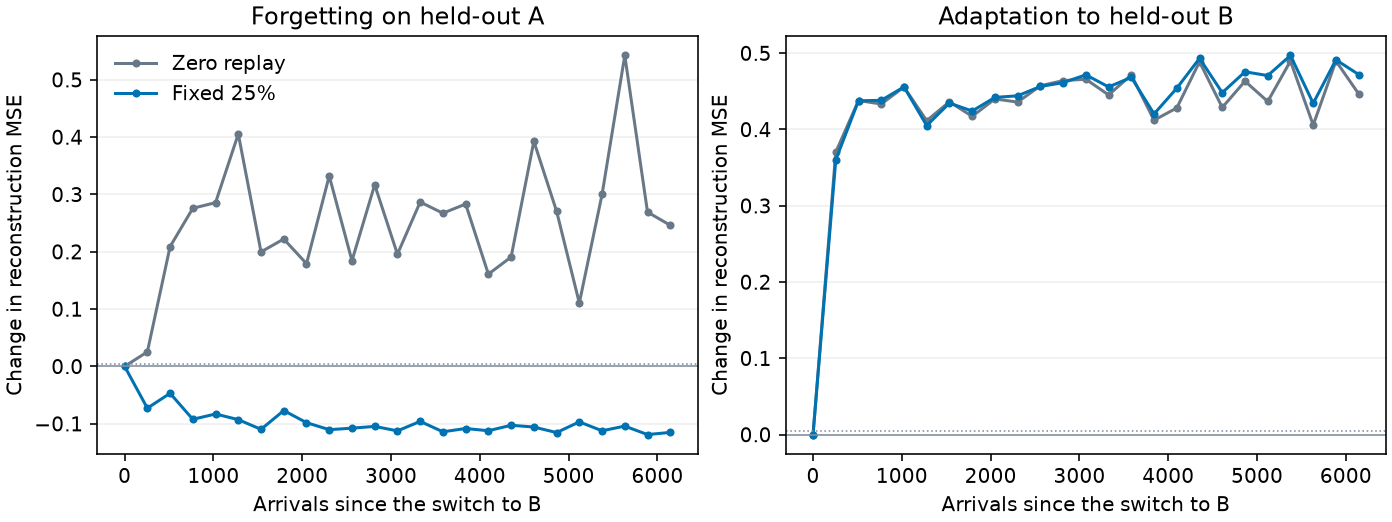